In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

from src.data import load_model_data, FEATURE_GROUPS, NUMERIC_COLS, CATEGORICAL_COLS, CLASS_ORDER, SEED, RESULTS_DIR
from src.models import Model
from src.evaluation import fit_evaluate, evaluate, bootstrap_diff, full_proba
from src.plotting import use_style, save, heatmap, SEQUENTIAL, DIVERGING, MODEL_COLORS, MODEL_MARKERS

use_style()
X, y, X_test, y_test = load_model_data()
params = json.loads((RESULTS_DIR / "02_selected_params.json").read_text())
best = pd.read_csv(RESULTS_DIR / "03_cv_summary.csv", index_col=0).drop("Dummy")["macro_f1_mean"].idxmax()
MODELS = ["LogReg", "kNN", "NaiveBayes", "RandomForest", "XGBoost"]
METRICS = ["macro_f1", "balanced_accuracy", "detection_rate", "false_alarm_rate"]

fitted, base_pred, base_scores = {}, {}, {}
for name in MODELS:
    fitted[name] = Model(name, params[name]).fit(X, y)
    proba = full_proba(fitted[name].predict_proba(X_test), fitted[name].classes_)
    base_pred[name] = proba.argmax(axis=1)
    base_scores[name] = evaluate(y_test, proba)[0]
print(best, {m: round(float(s["macro_f1"]), 4) for m, s in base_scores.items()})

XGBoost {'LogReg': 0.3507, 'kNN': 0.428, 'NaiveBayes': 0.2332, 'RandomForest': 0.52, 'XGBoost': 0.5152}


In [2]:
groups = {**FEATURE_GROUPS, "categorical": CATEGORICAL_COLS}
rows, per_class = [], {}
for group, cols in groups.items():
    numeric = [c for c in NUMERIC_COLS if c not in cols]
    categorical = [c for c in CATEGORICAL_COLS if c not in cols]
    for name in MODELS:
        model = Model(name, params[name], numeric_cols=numeric, categorical_cols=categorical)
        scores, _, proba = fit_evaluate(model, X, y, X_test, y_test)
        low, high = bootstrap_diff(y_test, base_pred[name], proba.argmax(axis=1))
        rows.append({"group": group, "model": name,
                     **{f"delta_{m}": scores[m] - base_scores[name][m] for m in METRICS},
                     "delta_macro_f1_ci_low": low, "delta_macro_f1_ci_high": high})
        if name == best:
            per_class[group] = [scores[f"f1_{c}"] - base_scores[name][f"f1_{c}"] for c in CLASS_ORDER]
    print(group)
ablation = pd.DataFrame(rows)
ablation.to_csv(RESULTS_DIR / "05_ablation.csv", index=False)
ablation_per_class = pd.DataFrame(per_class, index=CLASS_ORDER).T
ablation_per_class.to_csv(RESULTS_DIR / f"05_ablation_per_class_{best}.csv")
ablation.pivot(index="group", columns="model", values="delta_macro_f1").loc[list(groups), MODELS].round(4)

volume


timing


ttl


tcp_header


app_content


conn_history


categorical


model,LogReg,kNN,NaiveBayes,RandomForest,XGBoost
group,,,,,
volume,-0.0151,-0.0748,0.0006,-0.1519,-0.1558
timing,-0.0072,0.0080,-0.0036,0.0085,0.0020
ttl,-0.0083,-0.0287,-0.0178,-0.0126,-0.0078
tcp_header,-0.0002,0.0017,0.0009,0.0017,0.0019
app_content,-0.0018,0.0071,0.0057,0.0002,0.0019
conn_history,-0.0166,0.0046,-0.0155,-0.0028,-0.0125
categorical,-0.0307,-0.0168,-0.0208,-0.0122,-0.0071


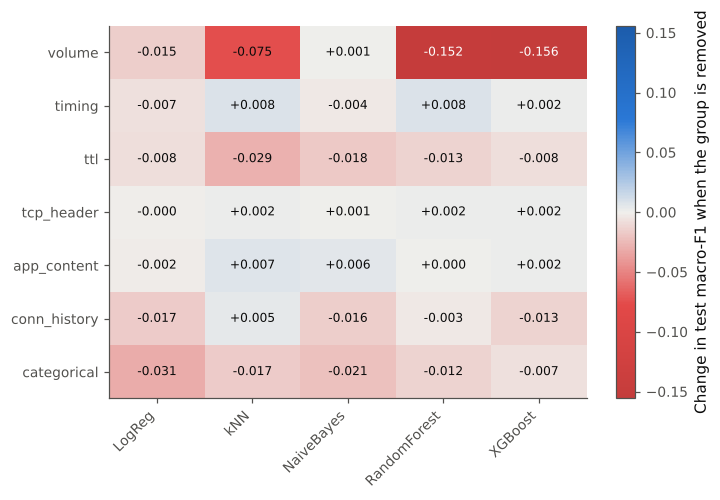

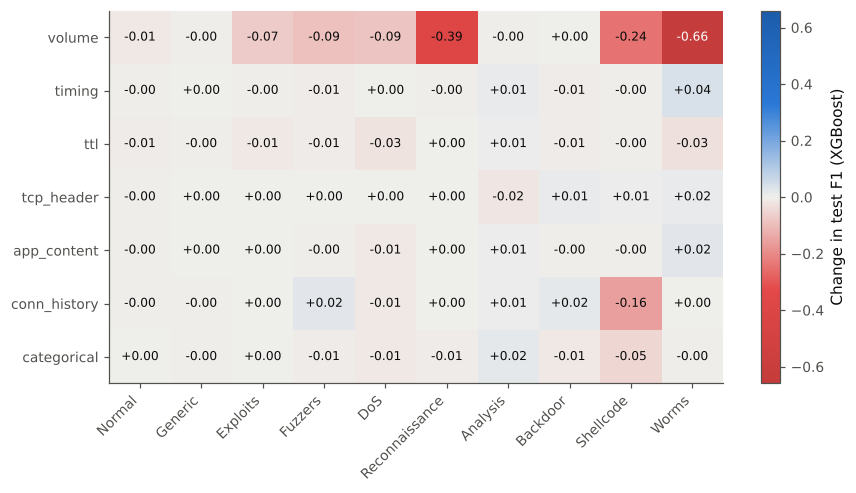

In [3]:
delta = ablation.pivot(index="group", columns="model", values="delta_macro_f1").loc[list(groups), MODELS]
limit = np.abs(delta.to_numpy()).max()
fig, ax = plt.subplots(figsize=(7, 4.4))
image = heatmap(ax, delta.to_numpy(), DIVERGING, -limit, limit, fmt="{:+.3f}", xlabels=MODELS, ylabels=delta.index)
fig.colorbar(image, ax=ax, label="Change in test macro-F1 when the group is removed")
save(fig, "05_ablation_macro_f1.png")
plt.show()

limit = np.abs(ablation_per_class.to_numpy()).max()
fig, ax = plt.subplots(figsize=(9, 4.4))
image = heatmap(ax, ablation_per_class.to_numpy(), DIVERGING, -limit, limit, fmt="{:+.2f}",
                xlabels=CLASS_ORDER, ylabels=ablation_per_class.index)
fig.colorbar(image, ax=ax, label=f"Change in test F1 ({best})")
save(fig, f"05_ablation_per_class_{best}.png")
plt.show()

In [4]:
medians = X[NUMERIC_COLS].median().to_numpy()
log_sigma = np.log1p(X[NUMERIC_COLS].to_numpy(dtype=float)).std(axis=0)
clean = X_test[NUMERIC_COLS].to_numpy(dtype=float)
log_clean = np.log1p(clean)


def perturb(kind, level, seed):
    rng = np.random.default_rng(SEED + seed)
    if kind == "noise":
        values = np.expm1(np.clip(log_clean + rng.normal(size=clean.shape) * level * log_sigma, 0, None))
    else:
        values = np.where(rng.random(clean.shape) < level, medians, clean)
    return pd.concat([pd.DataFrame(values, columns=NUMERIC_COLS), X_test[CATEGORICAL_COLS]], axis=1)


rows = [{"perturbation": kind, "level": 0.0, "seed": 0, "model": name, **base_scores[name]}
        for kind in ("noise", "missing") for name in MODELS]
for kind, levels in {"noise": [0.1, 0.25, 0.5, 1.0], "missing": [0.1, 0.25, 0.5]}.items():
    for level in levels:
        for seed in (0, 1):
            X_perturbed = perturb(kind, level, seed)
            for name in MODELS:
                proba = full_proba(fitted[name].predict_proba(X_perturbed), fitted[name].classes_)
                rows.append({"perturbation": kind, "level": level, "seed": seed, "model": name,
                             **evaluate(y_test, proba)[0]})
        print(kind, level)
perturbation = pd.DataFrame(rows)
perturbation.to_csv(RESULTS_DIR / "05_perturbation.csv", index=False)
curves = perturbation.groupby(["perturbation", "level", "model"])[METRICS].mean()
curves.unstack("model")["macro_f1"].round(4)

noise 0.1


noise 0.25


noise 0.5


noise 1.0


missing 0.1


missing 0.25


missing 0.5


model               LogReg  NaiveBayes  RandomForest  XGBoost     kNN
perturbation level                                                   
missing      0.00   0.3507      0.2332        0.5200   0.5152  0.4280
             0.10   0.2511      0.2305        0.4870   0.4673  0.3893
             0.25   0.1799      0.2285        0.4233   0.4049  0.3372
             0.50   0.1373      0.2336        0.2861   0.2797  0.2358
noise        0.00   0.3507      0.2332        0.5200   0.5152  0.4280
             0.10   0.3355      0.2369        0.3473   0.2774  0.4123
             0.25   0.2818      0.2449        0.3038   0.2426  0.3949
             0.50   0.2154      0.2312        0.2640   0.2125  0.3675
             1.00   0.1442      0.2010        0.2284   0.1760  0.3139

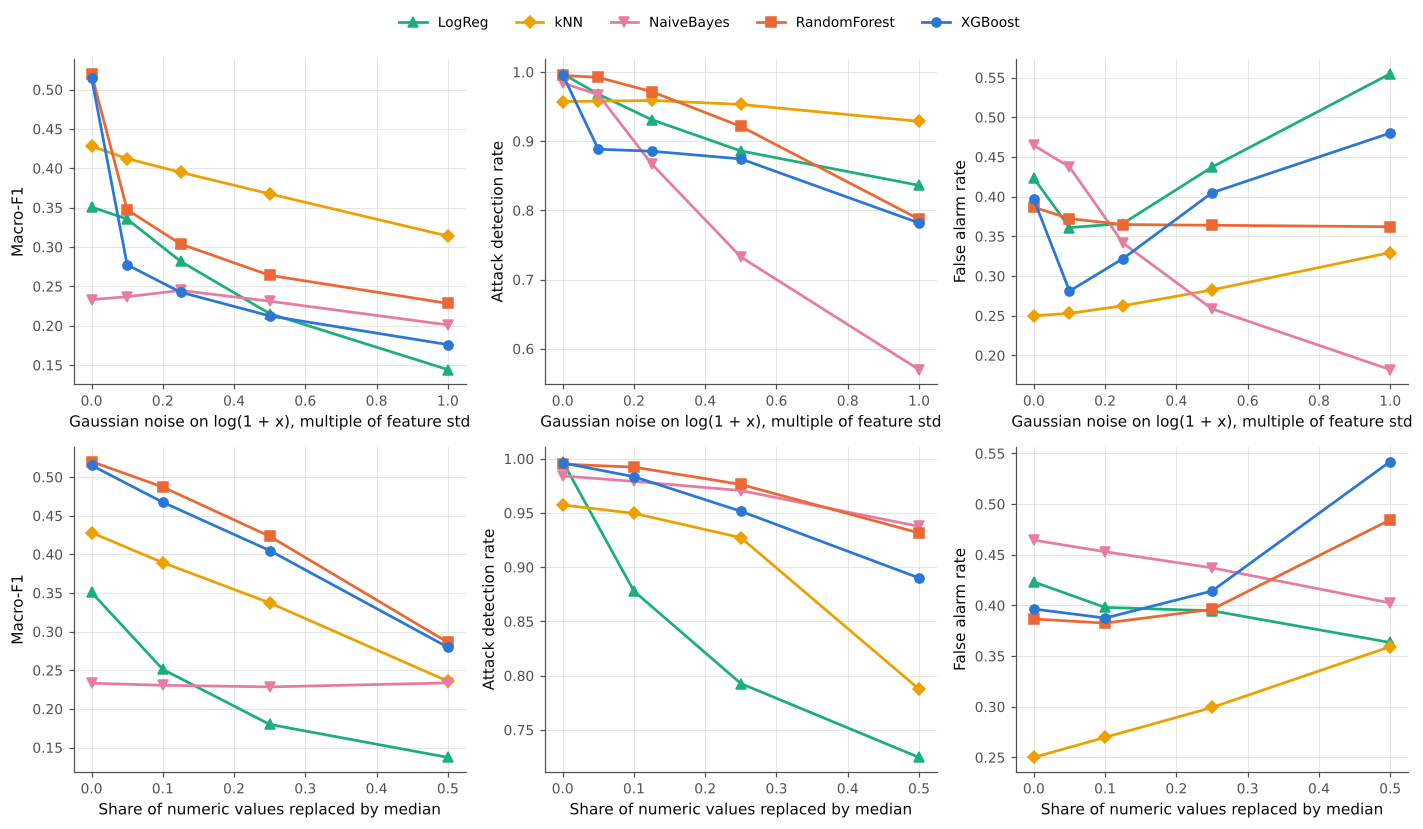

In [5]:
labels = {"macro_f1": "Macro-F1", "detection_rate": "Attack detection rate", "false_alarm_rate": "False alarm rate"}
xlabels = {"noise": "Gaussian noise on log(1 + x), multiple of feature std", "missing": "Share of numeric values replaced by median"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for row, kind in enumerate(["noise", "missing"]):
    for col, metric in enumerate(labels):
        ax = axes[row, col]
        for name in MODELS:
            series = curves.loc[kind][metric].xs(name, level="model")
            ax.plot(series.index, series.values, marker=MODEL_MARKERS[name], color=MODEL_COLORS[name], label=name)
        ax.set_xlabel(xlabels[kind])
        ax.set_ylabel(labels[metric])
fig.tight_layout()
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=len(MODELS), bbox_to_anchor=(0.5, 1.0))
save(fig, "05_perturbation.png")
plt.show()

In [6]:
rows = []
for k in range(1, len(CLASS_ORDER)):
    keep = y != k
    encoder = LabelEncoder().fit(y[keep])
    target = y_test == k
    for name in MODELS:
        model = Model(name, params[name]).fit(X[keep], encoder.transform(y[keep]))
        predicted = encoder.classes_[model.predict_proba(X_test[target]).argmax(axis=1)]
        rows.append({"held_out": CLASS_ORDER[k], "model": name, "test_records": int(target.sum()),
                     "missed_when_unseen": (predicted == 0).mean(),
                     "missed_when_known": (base_pred[name][target] == 0).mean(),
                     "most_frequent_prediction": CLASS_ORDER[np.bincount(predicted, minlength=len(CLASS_ORDER)).argmax()]})
    print(CLASS_ORDER[k])
held_out = pd.DataFrame(rows)
held_out.to_csv(RESULTS_DIR / "05_leave_one_attack_out.csv", index=False)
held_out.pivot(index="held_out", columns="model", values="missed_when_unseen").loc[CLASS_ORDER[1:], MODELS].round(3)

Generic


Exploits


Fuzzers


DoS


Reconnaissance


Analysis


Backdoor


Shellcode


Worms


model,LogReg,kNN,NaiveBayes,RandomForest,XGBoost
held_out,,,,,
Generic,0.002,0.447,0.204,0.000,0.001
Exploits,0.019,0.091,0.201,0.011,0.013
Fuzzers,0.426,0.645,0.097,0.557,0.523
DoS,0.012,0.017,0.021,0.006,0.005
Reconnaissance,0.000,0.074,0.002,0.002,0.002
Analysis,0.069,0.027,0.049,0.000,0.024
Backdoor,0.000,0.039,0.010,0.000,0.000
Shellcode,0.000,0.066,0.003,0.003,0.003
Worms,0.000,0.000,0.000,0.000,0.000


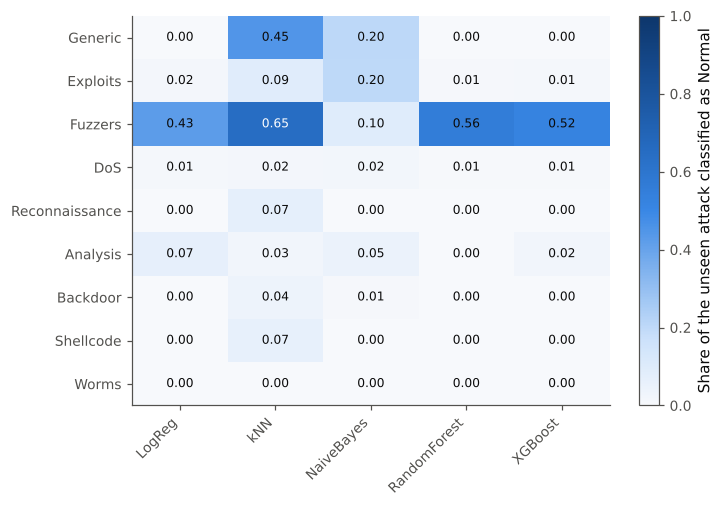

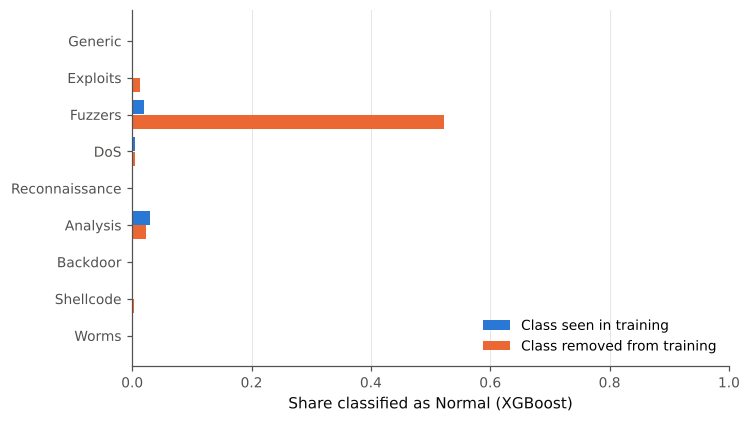

In [7]:
missed = held_out.pivot(index="held_out", columns="model", values="missed_when_unseen").loc[CLASS_ORDER[1:], MODELS]
fig, ax = plt.subplots(figsize=(7, 4.6))
image = heatmap(ax, missed.to_numpy(), SEQUENTIAL, 0, 1, xlabels=MODELS, ylabels=missed.index)
fig.colorbar(image, ax=ax, label="Share of the unseen attack classified as Normal")
save(fig, "05_leave_one_attack_out.png")
plt.show()

known = held_out[held_out["model"] == best].set_index("held_out").loc[CLASS_ORDER[1:]]
positions = np.arange(len(known))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(positions - 0.2, known["missed_when_known"], height=0.38, color=MODEL_COLORS["XGBoost"],
        label="Class seen in training")
ax.barh(positions + 0.2, known["missed_when_unseen"], height=0.38, color=MODEL_COLORS["RandomForest"],
        label="Class removed from training")
ax.set_yticks(positions, known.index)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel(f"Share classified as Normal ({best})")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, f"05_leave_one_attack_out_{best}.png")
plt.show()

In [8]:
noise = curves.loc["noise"]["macro_f1"].unstack("model")
missing = curves.loc["missing"]["macro_f1"].unstack("model")
ablation_drop = ablation.loc[ablation.groupby("model")["delta_macro_f1"].idxmin()].set_index("model")
summary = pd.DataFrame({
    "clean_macro_f1": {m: base_scores[m]["macro_f1"] for m in MODELS},
    "macro_f1_noise_0.5": noise.loc[0.5],
    "relative_drop_noise_0.5": 1 - noise.loc[0.5] / noise.loc[0.0],
    "macro_f1_missing_0.25": missing.loc[0.25],
    "relative_drop_missing_0.25": 1 - missing.loc[0.25] / missing.loc[0.0],
    "mean_missed_when_unseen": held_out.groupby("model")["missed_when_unseen"].mean(),
    "most_damaging_group": ablation_drop["group"],
    "most_damaging_group_delta": ablation_drop["delta_macro_f1"],
}).loc[MODELS]
summary.to_csv(RESULTS_DIR / "05_robustness_summary.csv")
summary.round(4)

,clean_macro_f1,macro_f1_noise_0.5,relative_drop_noise_0.5,macro_f1_missing_0.25,relative_drop_missing_0.25,mean_missed_when_unseen,most_damaging_group,most_damaging_group_delta
LogReg,0.3507,0.2154,0.3859,0.1799,0.4870,0.0587,categorical,-0.0307
kNN,0.4280,0.3675,0.1414,0.3372,0.2122,0.1562,volume,-0.0748
NaiveBayes,0.2332,0.2312,0.0089,0.2285,0.0205,0.0653,categorical,-0.0208
RandomForest,0.5200,0.2640,0.4923,0.4233,0.1859,0.0643,volume,-0.1519
XGBoost,0.5152,0.2125,0.5875,0.4049,0.2141,0.0634,volume,-0.1558
